<a href="https://colab.research.google.com/github/Pulakspbl/Machine-learning-in-Python-with-scikit-learn/blob/main/Linear_regression_basic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Import libraries and prepare dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
# Dataset
data = {
    'Temperature': [15, 18, 20, 22, 25, 28, 30],
    'Sales': [120, 150, 180, 200, 240, 300, 350]
}

df = pd.DataFrame(data)

# Separate input and target
X = df[['Temperature']]
y = df['Sales']

print(df)

   Temperature  Sales
0           15    120
1           18    150
2           20    180
3           22    200
4           25    240
5           28    300
6           30    350


### 1. Linear Regression (Degree 1)

General equation:

$$
\hat{Y}=b_0+b_1X
$$
Fitted equation:
$$
\hat{Y}=-119.122+15.024X
$$

In [ ]:
# Linear Regression model
linear_model = LinearRegression()

# Train model
linear_model.fit(X, y)

# Make predictions
linear_pred = linear_model.predict(X)

# Display coefficients
print("Intercept:", linear_model.intercept_)
print("Coefficient:", linear_model.coef_[0])

print("Predictions:", linear_pred.round(2))

Intercept: -119.12195121951203
Coefficient: 15.024390243902431
Predictions: [106.24 151.32 181.37 211.41 256.49 301.56 331.61]



### 2. Quadratic Polynomial Regression (Degree 2)

General equation:

$$
\hat{Y}=b_0+b_1X+b_2X^2
$$
Fitted equation:
$$
\hat{Y}=121.256-7.263X+0.491X^2
$$


In [ ]:
# Generate polynomial features (degree 2)
poly2 = PolynomialFeatures(degree=2)

X_poly2 = poly2.fit_transform(X)

# Create and train model
quadratic_model = LinearRegression()
quadratic_model.fit(X_poly2, y)

# Predictions
quadratic_pred = quadratic_model.predict(X_poly2)

# Display coefficients
print("Intercept:", quadratic_model.intercept_)
print("Coefficients:", quadratic_model.coef_)

print("Predictions:", quadratic_pred.round(2))

Intercept: 121.2561741822202
Coefficients: [ 0.         -7.26311709  0.49138944]
Predictions: [122.87 149.73 172.55 199.3  246.8  303.14 345.61]


### 3. Cubic Polynomial Regression (Degree 3)

General equation:
$$
\hat{Y}=b_0+b_1X+b_2X^2+b_3X^3
$$
Fitted equation:
$$
\hat{Y}=-334.601+57.796X-2.507X^2+0.04472X^3
$$

In [ ]:
# Generate polynomial features (degree 3)
poly3 = PolynomialFeatures(degree=3)

X_poly3 = poly3.fit_transform(X)

# Create and train model
cubic_model = LinearRegression()
cubic_model.fit(X_poly3, y)

# Predictions
cubic_pred = cubic_model.predict(X_poly3)

# Display coefficients
print("Intercept:", cubic_model.intercept_)
print("Coefficients:", cubic_model.coef_)

print("Predictions:", cubic_pred.round(2))

Intercept: -334.60050568233646
Coefficients: [ 0.00000000e+00  5.77958384e+01 -2.50748939e+00  4.47192139e-02]
Predictions: [119.08 154.1  176.07 199.45 241.85 299.49 349.95]


In [ ]:
# Calculate evaluation metrics

results = {
    'Model': ['Linear', 'Quadratic', 'Cubic'],

    'MAE': [
        mean_absolute_error(y, linear_pred),
        mean_absolute_error(y, quadratic_pred),
        mean_absolute_error(y, cubic_pred)
    ],

    'MSE': [
        mean_squared_error(y, linear_pred),
        mean_squared_error(y, quadratic_pred),
        mean_squared_error(y, cubic_pred)
    ],

    'R2 Score': [
        r2_score(y, linear_pred),
        r2_score(y, quadratic_pred),
        r2_score(y, cubic_pred)
    ]
}

results_df = pd.DataFrame(results)

print(results_df.round(4))

       Model     MAE       MSE  R2 Score
0     Linear  9.1847  133.6585    0.9770
1  Quadratic  3.6591   19.9438    0.9966
2      Cubic  1.7008    5.2955    0.9991


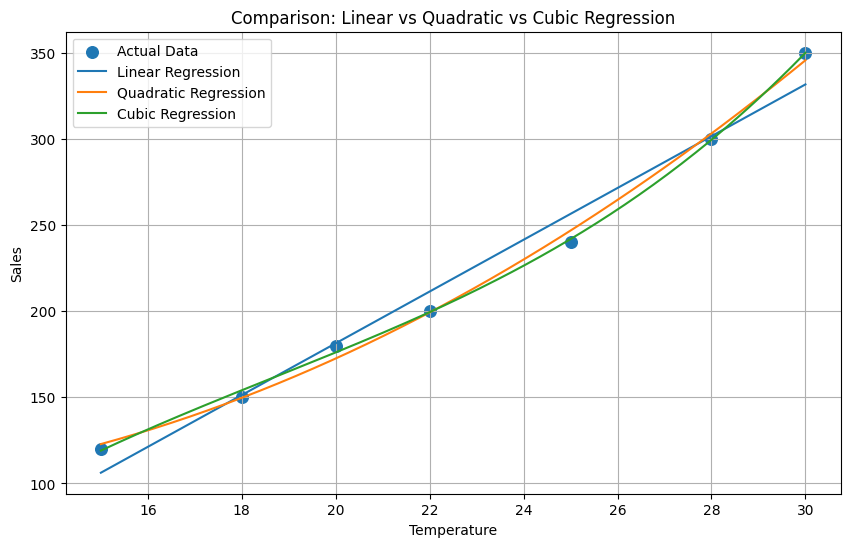

In [ ]:
# Generate smooth temperature values for plotting
X_range = pd.DataFrame({
    'Temperature': np.linspace(15, 30, 200)
})

# Linear predictions
linear_curve = linear_model.predict(X_range)

# Quadratic predictions
quadratic_curve = quadratic_model.predict(
    poly2.transform(X_range)
)

# Cubic predictions
cubic_curve = cubic_model.predict(
    poly3.transform(X_range)
)

# Plot actual observations
plt.figure(figsize=(10, 6))

plt.scatter(
    X, y,
    label='Actual Data',
    s=70
)

# Plot models
plt.plot(
    X_range, linear_curve,
    label='Linear Regression'
)

plt.plot(
    X_range, quadratic_curve,
    label='Quadratic Regression'
)

plt.plot(
    X_range, cubic_curve,
    label='Cubic Regression'
)

plt.xlabel('Temperature')
plt.ylabel('Sales')
plt.title('Comparison: Linear vs Quadratic vs Cubic Regression')

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error

# Data
df = pd.DataFrame({
    'Temperature': [15, 18, 20, 22, 25, 28, 30],
    'Sales': [120, 150, 180, 200, 240, 300, 350]
})

X = df['Temperature'].values
y = df['Sales'].values

# Prepare features and fit model
X_linear = sm.add_constant(X)
model_linear = sm.OLS(y, X_linear).fit()

# Evaluation metrics
preds_linear = model_linear.predict(X_linear)
rmse_linear = np.sqrt(mean_squared_error(y, preds_linear))

print("--- LINEAR REGRESSION ---")
print(f"R-squared:     {model_linear.rsquared:.4f}")
print(f"Adj R-squared: {model_linear.rsquared_adj:.4f}")
print(f"RMSE:          {rmse_linear:.4f}")
print(f"AIC:           {model_linear.aic:.4f}")
print(f"BIC:           {model_linear.bic:.4f}")
print("\n", model_linear.summary())


--- LINEAR REGRESSION ---
R-squared:     0.9770
Adj R-squared: 0.9723
RMSE:          11.5611
AIC:           58.1322
BIC:           58.0240

                             OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.977
Model:                            OLS   Adj. R-squared:                  0.972
Method:                 Least Squares   F-statistic:                     212.0
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           2.76e-05
Time:                        04:21:59   Log-Likelihood:                -27.066
No. Observations:                   7   AIC:                             58.13
Df Residuals:                       5   BIC:                             58.02
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025   

/usr/local/lib/python3.13/dist-packages/statsmodels/regression/linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 7 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


In [ ]:
# Prepare features (X and X^2) and fit model
X_quad = sm.add_constant(np.column_stack((X, X**2)))
model_quad = sm.OLS(y, X_quad).fit()

# Evaluation metrics
preds_quad = model_quad.predict(X_quad)
rmse_quad = np.sqrt(mean_squared_error(y, preds_quad))

print("--- QUADRATIC REGRESSION ---")
print(f"R-squared:     {model_quad.rsquared:.4f}")
print(f"Adj R-squared: {model_quad.rsquared_adj:.4f}")
print(f"RMSE:          {rmse_quad:.4f}")
print(f"AIC:           {model_quad.aic:.4f}")
print(f"BIC:           {model_quad.bic:.4f}")
print("\n", model_quad.summary())

--- QUADRATIC REGRESSION ---
R-squared:     0.9966
Adj R-squared: 0.9948
RMSE:          4.4659
AIC:           46.8156
BIC:           46.6533

                             OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.995
Method:                 Least Squares   F-statistic:                     579.6
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           1.18e-05
Time:                        04:21:59   Log-Likelihood:                -20.408
No. Observations:                   7   AIC:                             46.82
Df Residuals:                       4   BIC:                             46.65
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025 

/usr/local/lib/python3.13/dist-packages/statsmodels/regression/linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 7 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


In [ ]:
# Prepare features (X, X^2, and X^3) and fit model
X_cubic = sm.add_constant(np.column_stack((X, X**2, X**3)))
model_cubic = sm.OLS(y, X_cubic).fit()

# Evaluation metrics
preds_cubic = model_cubic.predict(X_cubic)
rmse_cubic = np.sqrt(mean_squared_error(y, preds_cubic))

print("--- CUBIC REGRESSION ---")
print(f"R-squared:     {model_cubic.rsquared:.4f}")
print(f"Adj R-squared: {model_cubic.rsquared_adj:.4f}")
print(f"RMSE:          {rmse_cubic:.4f}")
print(f"AIC:           {model_cubic.aic:.4f}")
print(f"BIC:           {model_cubic.bic:.4f}")
print("\n", model_cubic.summary())

--- CUBIC REGRESSION ---
R-squared:     0.9991
Adj R-squared: 0.9982
RMSE:          2.3012
AIC:           39.5331
BIC:           39.3167

                             OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                     1094.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           4.68e-05
Time:                        04:21:59   Log-Likelihood:                -15.767
No. Observations:                   7   AIC:                             39.53
Df Residuals:                       3   BIC:                             39.32
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025     

/usr/local/lib/python3.13/dist-packages/statsmodels/regression/linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 7 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


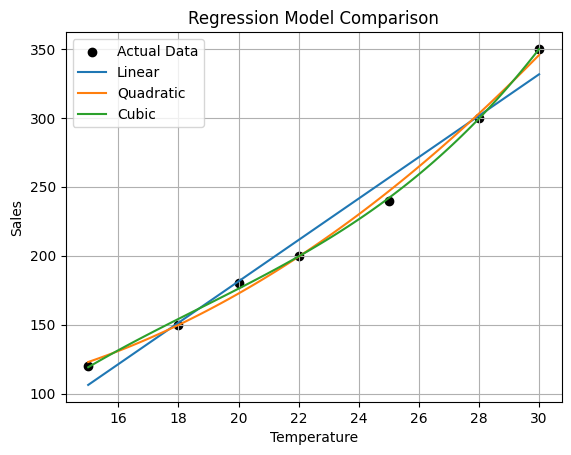

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Smooth temperature values
X_smooth = np.linspace(X.min(), X.max(), 100)

# Actual data
plt.scatter(X, y, color='black', label='Actual Data')

# Linear model
plt.plot(X_smooth, model_linear.predict(sm.add_constant(X_smooth)), label='Linear')

# Quadratic model
plt.plot(X_smooth, model_quad.predict(sm.add_constant(
    np.column_stack([X_smooth, X_smooth**2])
)), label='Quadratic')

# Cubic model
plt.plot(X_smooth, model_cubic.predict(sm.add_constant(
    np.column_stack([X_smooth, X_smooth**2, X_smooth**3])
)), label='Cubic')

plt.xlabel('Temperature')
plt.ylabel('Sales')
plt.title('Regression Model Comparison')
plt.legend()
plt.grid()
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_iris
import numpy as np

data= load_iris()

X = data.data
y = data.target



In [ ]:
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3